In [36]:
import os #permet d'utiliser des fonctionnalités du système d'exploitation (mkdir, lecture...)
import itertools
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score
import json

from torchvision.transforms.v2 import RandomRotation
from torchvision.transforms import v2
import torchvision.transforms as transforms

from torch.utils.data import Dataset, Subset
from torch.utils.data import DataLoader
import torch.optim as optim

from tensorflow.keras.datasets import mnist
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

Import des données MNIST. Source : https://www.codeandcortex.fr/initiation-deep-learning-dataset-mnist/ et https://www.digitalocean.com/community/tutorials/mnist-dataset-in-python

In [17]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [18]:
print('X_train: ' + str(X_train.shape))
print('Y_train: ' + str(y_train.shape))
print('X_test:  '  + str(X_test.shape))
print('Y_test:  '  + str(y_test.shape))

X_train: (60000, 28, 28)
Y_train: (60000,)
X_test:  (10000, 28, 28)
Y_test:  (10000,)


60 000 images de train, 28x28
10 000 images test, 28x28

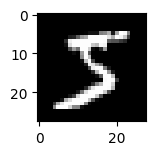

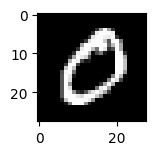

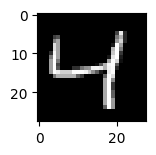

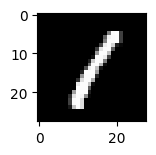

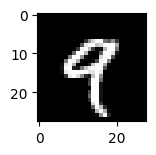

In [61]:
from matplotlib import pyplot
for i in range(5):  
    pyplot.subplot(330 + 1 + i)
    pyplot.imshow(X_train[i], cmap=pyplot.get_cmap('gray'))
    pyplot.show()

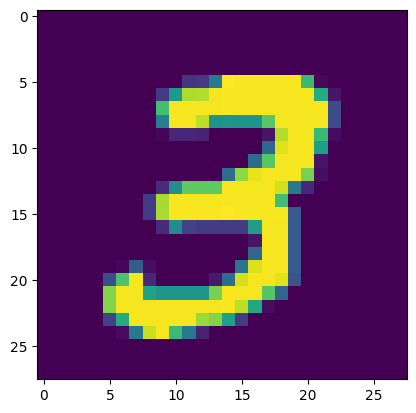

In [25]:
import matplotlib.pyplot as plt
plt.imshow(X_train[7])

**Rotation aléatoire** en utilisant librairie pytorch : https://docs.pytorch.org/vision/main/generated/torchvision.transforms.v2.RandomRotation.html

In [58]:
import torch
import matplotlib.pyplot as plt
from torchvision.transforms import RandomRotation

# Rotation aléatoire entre -180° et +180°
rr = RandomRotation(degrees=180)

X_rotation = []

Nombre = 500

for i in range(Nombre):

    # Récupérer l'image i
    image = torch.as_tensor(X_train[i], dtype=torch.float32)

    # Ajouter la dimension du canal : (28, 28) -> (1, 28, 28)
    if image.ndim == 2:
        image = image.unsqueeze(0)

    # Appliquer la rotation
    image_rotation = rr(image)

    X_rotation.append(image_rotation)

# Convertir la liste en un seul tenseur
X_rotation = torch.stack(X_rotation)

print("Dimensions :", X_rotation.shape)


Dimensions : torch.Size([500, 1, 28, 28])


**Afficher les images avec rotation**

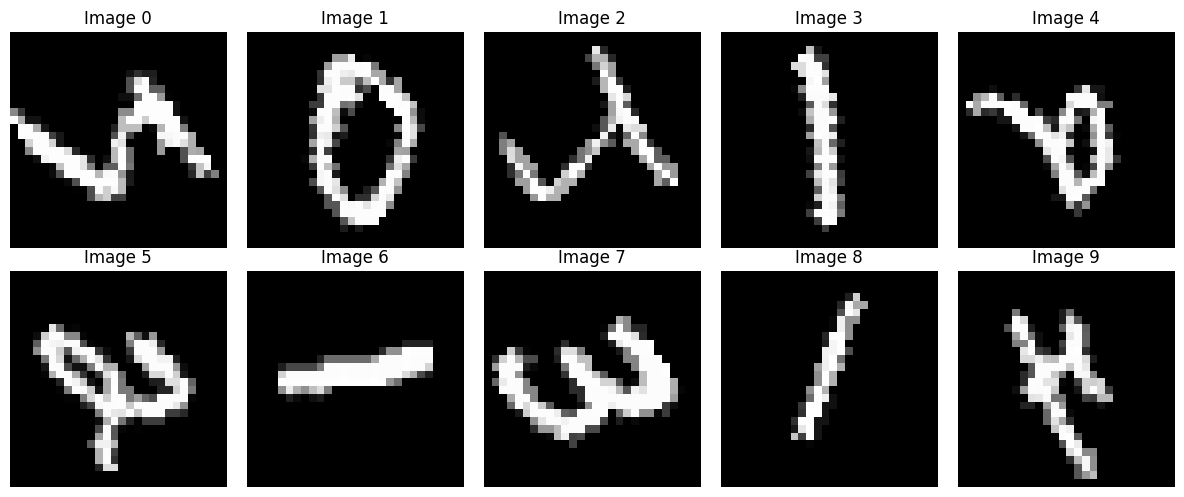

In [60]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_rotation[i].squeeze(), cmap="gray")
    ax.set_title(f"Image {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()